<div style="display: flex; justify-content: space-between; align-items: center;">
    <img src="../Assets/EUMETSAT_logo.png" alt="EUMETSAT" width="200" height="100">
    <div style="flex-grow: 1;margin-right: 70px;"></div>
    <img src="../Assets/emy_logo.png" alt="HNMS" width="150" height="50">
    <div style="flex-grow: 1; margin-right: 70px;"></div>
    <img src="../Assets/logo-hsaf.png" alt="HSAF" width="300" height="100">
</div>
       Training activity of EUMETSAT and Hellenic National Meteorological Service (HNMS) for HSAF products

---
#### International Autumn School on Satellite Data Analysis, Athens 09 - 13 November 2026
---

# Visualize H-SAF H68 product notebook

### Authors: 
* Konstantinos Kolokythas (konstantinos.kolokythas@hnms.gr)
* Alexandros Paraskevas (alexandros.paraskevas@hnms.gr)

## **Precipitation HSAF Product: P-IN-PMW (H68)**

**P**= Product is for Precipitaion

**IN**= Type of precipitation , in this case Instantaneous Precipitation Rate

**PMW**= Refers to the radiometer, in this case PMW (Passive MicroWave)

Gridded MW instantaneous precipitation rate based on intercalibrated PMW instantaneous precipitation rate estimates
on extended H SAF area</p>
**Example of H-68 HSAF product:**
<div>
    <img src="../Assets/h68.png" alt="H68" width="40%">
</div>

### Precipitation rate estimation over 30 minutes
 based on instantaneous precipitation rate estimates available from P-IN-SSMIS (H01), P-IN-MHS (H02B), P-IN-ATMS (H18), H-AUX-17, H-AUX-20, combined and intercalibrated.

**Coverage:** MSG 0 Degree Full Disk area [60°S-75°N lat, 60° W-60° E long]

**Spatial Resolution:** Regular grid at 0.25°x0.25° resolution.

**Accuracy:** 
|  Precipitation range | Threshold | Target | Optimal |
|----------------------|-----------|--------|---------|
| > 1 mm/24h           | .50       | .60    |   .65   |

Accuracy requirements for product P-IN-PMW (CC, Correlation Coeficient with reference measurements.)

**Timeliness:** 4 hours

- **Precipitation Range**: This column specifies different categories of precipitation based on their rates. There are three categories:
   - "> 10 mm/24h" represents precipitation rates greater than 10 millimeters per 24hour.

- **Threshold CC**: This column specifies the threshold level of accuracy, represented as the Correlation Coeficient (CC), for the product "P-IN-PMW" under each precipitation range. For instance, for precipitation rates greater than 1 mm/24h, the threshold CC is .50.

- **Target RMSE (%)**: This column specifies the desired level of accuracy, represented as the Correlation Coeficient (CC), for the product "P-IN-PMW" under each precipitation range. For instance, for precipitation rates greater than 1 mm/24h, the target CC is .60.

- **Optimal RMSE (%)**: This column represents the ideal or optimal level of accuracy, represented as the Correlation Coeficient (CC), for the product "P-IN-PMW" under each precipitation range. For instance, for precipitation rates greater than 1 mm/24h, the optimal CC is .65. 

**Examples:**

- For precipitation rates greater than 1 mm/24h, if the product "P-IN-PMW" achieves a CC 0.60, it would meet the Target CC requirement but not the Optimal CC, which is 0.65.

More iformation is available to : 
* <a href="https://hsaf.meteoam.it/products/precipitation" target="_blank">Precipitation </a>
* <a href="https://hsaf.meteoam.it/service/pdf/SAF_HSAF_PUM-H68_v1.0.pdf" target="_blank">Product User Manual (PUM) </a>
* <a href="https://hsaf.meteoam.it/service/pdf/saf_hsaf_pvr-68.pdf" target="_blank">Product Validation Report (PVR) </a>
* <a href="https://hsaf.meteoam.it/service/pdf/SAF_HSAF_ATBD-H68_v3.0.pdf" target="_blank">Algorithm Theoretical Baseline Document (ATBD) </a>

## Data Availability

H-68 data are available from ***EUMETCast*** and ***HSAF*** portal site:
* **EUMETCast Satellite:** 
Data is received under the Channel: *E1B-SAF-5*.

Their filename is: *S-HSAF-h68_20220508_203000_205959_hea.nc.gz*

* **EUMETCast Terrestrial:** 
Data is received under the Channel: *T01-SAF*.

Their filename is: *S-HSAF-h68_20220508_203000_205959_hea.nc.gz*


* **HSAF -site:**
Data is stored in raw and jpeg format

Their filename is: *h68_20211026_230000_232959_hea.nc.gz*
<div style="display: flex; justify-content: space-between; align-items: center;">
    <img src="../Assets/H68_place_order.png" alt="Image" width="50%">
    <img src="../Assets/H68_quick_donwload.png" alt="Image" width="50%">
</div>

    
**Important:** Please note that there is a difference in filenames between EUMECast and the HSAF portal. It is important to keep this distinction in mind when writing code or working with data from these sources.

Further information pertaining to the H-68 product, as well as comprehensive reception details, can be accessed through the following source <a href="https://user.eumetsat.int/catalogue/EO:EUM:DAT:0623/overview" target="_blank">EUMETSAT Product Navigator </a>.
<div>
    <img src="../Assets/H68_product_navigator.png" alt="Image" width="90%">

## This module has the following outline
* [1 - Load required libraries](#1---Load-required-libraries)
* [2 - Load data](#2---Load-Data)
* [3 - Define Constants/Variables](#3---Define-Constants/Variables)
* [4 - Generate a plot of H-68 data](#4---Generate-a-plot-of-H-68-data)
* [5 - Get the Rain Rate for the requested lat and lon](#5---Get-the-Rain-Rate-for-the-requested-lat-and-lon)

<h2 id="load_libraries">1 - Load required libraries</h2>

The following libraries are necessary

In [1]:
import gzip
import shutil
import os

import numpy as np
#%pip install xarray
import xarray as xr

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import get_cmap
from matplotlib.colors import ListedColormap
#%pip install cartopy
#%pip install netCDF4
from cartopy import crs as ccrs
import cartopy.feature as cfeature

import datetime

1. **gzip**:
   - The `gzip` module is a Python module for working with GZIP (GNU Zip) compressed files. It provides functions for compression and decompression of files using the GZIP format.

2. **shutil**:
   - The `shutil` module is a Python module that provides a higher-level interface for file operations and manipulation. It includes functions for copying, moving, and deleting files and directories.

3. **os**:
   - The `os` module is a part of the Python standard library and provides functions for interacting with the operating system. It allows you to perform various file and directory operations, manipulate file paths, and more.

4. **numpy**:
   - `numpy` is a fundamental library for scientific computing in Python. It provides support for multidimensional arrays, mathematical functions, and tools for working with arrays, making it a crucial library for data manipulation and numerical computations.

5. **xarray**:
   - `xarray` is a Python library designed for working with labeled multi-dimensional arrays. It is particularly useful for handling and analyzing multidimensional data, such as climate data or time series data.

6. **matplotlib**:
    - `matplotlib` is a popular Python library for creating static, animated, and interactive visualizations. It provides a wide range of functions and tools for creating various types of plots and charts.

7. **cartopy.crs**:
    - `cartopy` is a library for cartographic projections and geospatial data visualization. The `crs` module within Cartopy provides support for defining and working with different coordinate reference systems.

8. **cartopy.feature**:
    - `cartopy.feature` provides a collection of pre-defined geospatial features, such as coastlines, rivers, and political boundaries, that can be used in Cartopy maps to enhance the visualization of geospatial data.
 
9. **datetime**:
    - `datetime` supplies classes to work with date and time. These classes provide a number of functions to deal with dates, times, and time intervals.

## <a id='load_data'></a>2 - Load Data

In [2]:
# Define the Zipped and Unzipped H68 filename
zippedFileName = 'h68_20261001_070000_072959_hea.nc.gz'

unZippedFileName = zippedFileName.rsplit('.', 1)[0]

# Extract Satellite Name from the Filename
satelliteName = unZippedFileName.split('_')[3]

# Unzip the H68 file and retrieve the data to an xarray dataset
# Open the compressed file for reading ('rb' mode)
with gzip.open('../data/h68'+'/'+zippedFileName, 'rb') as f_in:
    # Create an uncompressed file for writing ('wb' mode)
    with open('../temp/h68'+'/'+unZippedFileName, 'wb') as f_out:
        # Copy the contents of the compressed file to the uncompressed file
        shutil.copyfileobj(f_in, f_out)

# Extract date and time from the file attributes
date = unZippedFileName.split('_',1)[1][:8]
endTime = unZippedFileName.rsplit('_',2)[1][:6]

# Open and read the data from the uncompressed file using xarray
h68DataSet = xr.open_dataset('../temp/h68'+'/'+unZippedFileName)

#### Explore the data of H-68 product

In [3]:
h68DataSet

<xarray.Dataset> Size: 13MB
Dimensions:          (xc: 540, yc: 480)
Coordinates:
    lat              (xc) float64 4kB ...
    lon              (yc) float64 4kB ...
Dimensions without coordinates: xc, yc
Data variables:
    rr               (xc, yc) float64 2MB ...
    TotalCount       (xc, yc) float64 2MB ...
    CrossTrackCount  (xc, yc) float64 2MB ...
    ConicalCount     (xc, yc) float64 2MB ...
    phase            (xc, yc) float64 2MB ...
    qind             (xc, yc) float64 2MB ...
    IdSensorBin      (xc, yc) uint32 1MB ...
Attributes:
    Creation Date:  01-Oct-2026 10:50:21
    Version:        1.0
    Conventions:    CF-1.5
    Title:          Half Hour Gridded Mean Precipitation Rate
    Institution:    Institute of Atmospheric Sciences and Climate - Italian N...
    Source:         H01, H02B, H18, H-AUX-17 and H-AUX-20 precipitation rate ...
    Resolution:     The product is provided on a regular grid at 0.25x0.25 re...

In [4]:
# Check dimensions and their sizes
print("Dimensions:", h68DataSet.dims)

Dimensions: FrozenMappingWarningOnValuesAccess({'xc': 540, 'yc': 480})


In [5]:
# List variables in the dataset
print("Variables:", h68DataSet.variables)

Variables: Frozen({'lat': <xarray.Variable (xc: 540)> Size: 4kB
[540 values with dtype=float64]
Attributes:
    long_name:  latitude
    units:      degrees_north, 'lon': <xarray.Variable (yc: 480)> Size: 4kB
[480 values with dtype=float64]
Attributes:
    long_name:  longitude
    units:      degrees_east, 'rr': <xarray.Variable (xc: 540, yc: 480)> Size: 2MB
[259200 values with dtype=float64]
Attributes:
    long_name:   Precipitation rate estimation over 30 minutes
    short_name:  rr
    units:       mm/h
    FillValue:   NaN, 'TotalCount': <xarray.Variable (xc: 540, yc: 480)> Size: 2MB
[259200 values with dtype=float64]
Attributes:
    long_name:   Total sensors count
    short_name:  TotalCount
    units:       #
    FillValue:   NaN, 'CrossTrackCount': <xarray.Variable (xc: 540, yc: 480)> Size: 2MB
[259200 values with dtype=float64]
Attributes:
    long_name:   Cross-track sensors count
    short_name:  CrossTrackCount
    units:       #
    FillValue:   NaN, 'ConicalCount': <xar

In [6]:
# Explore data values of 'rr' (Rainfall Rate)
rr_data = h68DataSet['rr'].values
print("Shape of 'rr' data:", rr_data.shape)
print("Mean rr:", np.nanmean(rr_data))
print("Minimum rr:", np.nanmin(rr_data))
print("Maximum rr:", np.nanmax(rr_data))

Shape of 'rr' data: (540, 480)
Mean rr: 0.09217052797872226
Minimum rr: 0.0
Maximum rr: 24.674966207419537


## <a id='define_const-vars'></a>3 - Define Constants/Variables

In [7]:
# Min threshold for rain rate [mm/hr] to filter out noise
RR_MIN = 0.25 #page 28 of Doc.No: SAF/HSAF/PVR-01/1.1

# Define the area extent for the plot
EXTENT = [10, 40, 30, 50]

# Define the min and max level for the plot
VMIN = 0
VMAX = 30

# Define Fill Value (a commonly used value to indicate missing or undefined data)
fillValue = -9.99

# Define the resolution for the cartopy features (10m resolution for coastline and other map features)
RESOLUTION = '10m'

# Define the colormap (jet colormap with custom modifications)
jet = matplotlib.colormaps['jet']   # Get the 'jet' colormap

# Create a linear gradient of colors from 'jet'
newColors = jet(np.linspace(0, 1, 256))

# Define a semi-transparent white color
white = np.array([256/256, 256/256, 256/256, 0.5])

# Replace the first threshold colors with the semi-transparent white
newColors[:1, :] = white

# Create a new colormap with the modified colors
CMAP = ListedColormap(newColors)

In [8]:
# Filter out values<RR_MIN (produces nan values)
h68DataSet = h68DataSet.where(h68DataSet.rr > RR_MIN)

# Extract the 'rr' variable (rain rate) from the h68DataSet
rr = h68DataSet['rr']
rr = rr.fillna(0) #transform nan values to zero

# Extract the 'lon' variable (longitude) from the h68DataSet
lon = h68DataSet['lon']

# Extract the 'lat' variable (latitude) from the h68DataSet
lat = h68DataSet['lat']

## <a id='gen_save_fig'></a>4 - Generate a plot of H-68 data

* Figure initialization
* Set the extent area and projection
* Add features
* Define the bounds of the data
* Plot the pcolormesh and colorbar
* Save the figure in /out folder

### Full Coverage

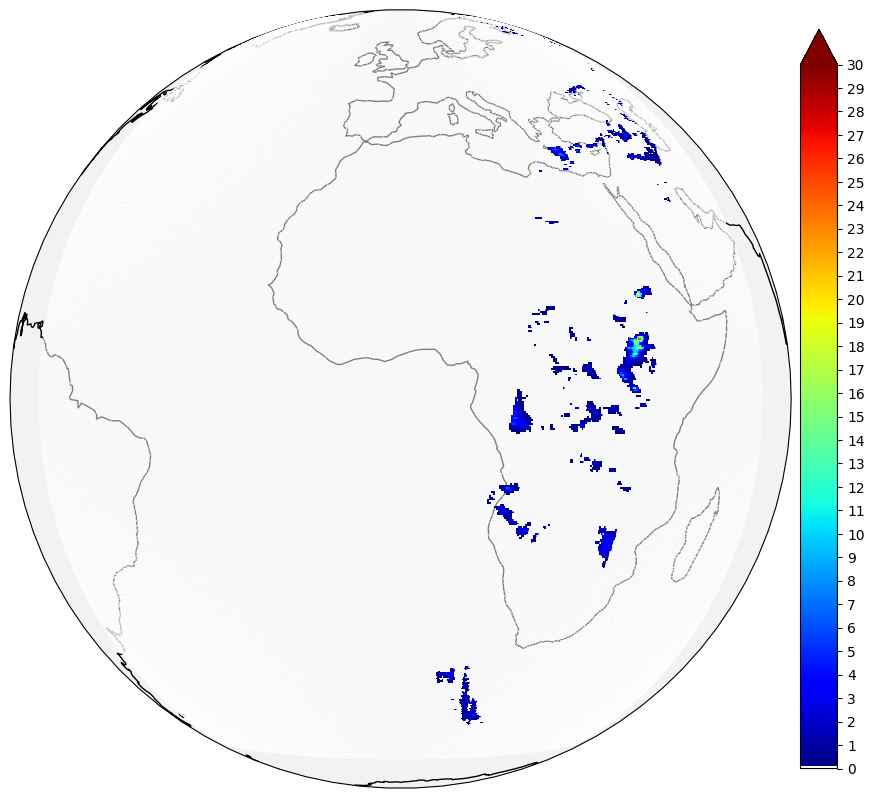

In [9]:
# Initialize the figure
plt.figure(figsize=(12,12)) # Create a figure with a specified size
PROJ = ccrs.Geostationary() # Define the projection (Geostationary projection)
ax = plt.axes(projection=PROJ) # Set the axes
ax.coastlines(resolution='110m') # Add coastline
ax.set_global() # Set global view
ax.set_facecolor('0.95') # Set the facecolor to make visible area distinguishable
# Create a pcolormesh plot with specified properties
mapRR = ax.pcolormesh(lon, lat, rr,
                       transform = ccrs.PlateCarree(), vmin=VMIN, vmax=VMAX, cmap=CMAP, zorder=30)
# Define color scale bounds
bounds = np.arange(0,VMAX+1,1)
cbar = plt.colorbar(mapRR, ax=ax, shrink=0.8, pad=.01,  ticks = bounds, extend = 'max')

### Area of Interest

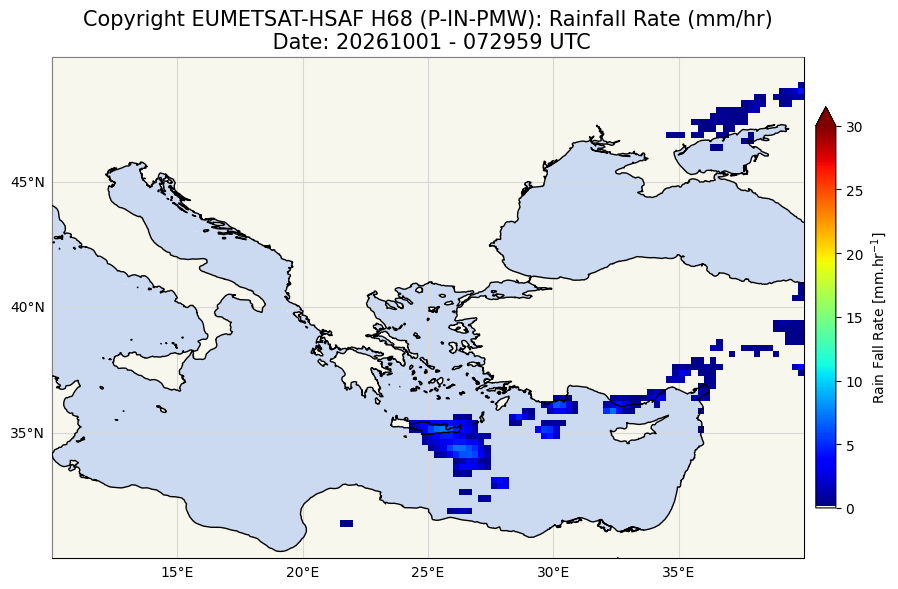

In [10]:
# Initialize the figure
fig = plt.figure(figsize=(12,6))  # Create a figure with a specified size

# Define the projection (Plate Carrée projection)
PROJ = ccrs.PlateCarree()

ax = fig.add_subplot(1,1,1,projection=PROJ)  # Add a subplot with a specified projection

# Set the extent area and projection of the plot
ax.set_extent(EXTENT, PROJ)

# Add ocean, land, coastlines, title, and gridlines features

# Create a NaturalEarthFeature for the ocean with specified properties
feature = cfeature.NaturalEarthFeature(category='physical', name='ocean', scale=RESOLUTION,
                                edgecolor='none',
                                facecolor=cfeature.COLORS['water'],zorder=0)
ax.add_feature(feature)  # Add the ocean feature to the plot

# Create a NaturalEarthFeature for the land with specified properties
feature = cfeature.NaturalEarthFeature(category='physical', name='land', scale=RESOLUTION,
                                edgecolor='none',
                                facecolor=cfeature.COLORS['land'],zorder=1)
ax.add_feature(feature)  # Add the land feature to the plot

ax.coastlines(resolution=RESOLUTION,zorder=100)  # Add coastlines to the plot

# Add a title to the plot
ax.set_title(f"Copyright EUMETSAT-HSAF H68 (P-IN-PMW): Rainfall Rate (mm/hr)\n \
Date: {date} - {endTime} UTC", size = 15)  # Set the plot title

# Create gridlines with specified properties
gl = ax.gridlines(draw_labels=True, xlocs=np.arange(EXTENT[0],EXTENT[1],5),
                    ylocs=np.arange(EXTENT[2],EXTENT[3],5), zorder=10)
gl.top_labels = False
gl.right_labels = False

# Plot the pcolormesh

# Define color scale bounds
bounds = np.arange(0,VMAX+1,5)

# Create a pcolormesh plot with specified properties
mapRR = ax.pcolormesh(lon, lat, rr,
                      transform=PROJ, vmin=VMIN, vmax=VMAX, cmap=CMAP, zorder=30)

# Add the colorbar
label = 'Rain Fall Rate [mm.hr$^{-1}$]'
cbar = plt.colorbar(mapRR, ax=ax, shrink=.8, pad=.01, label = label, ticks = bounds, extend = 'max')

fig.tight_layout()  # Adjust the layout of the figure for better appearance

# Save and Show the fig
figPath = os.path.join('../out/h68/',unZippedFileName.rsplit('.')[0]+'.png')
plt.savefig(figPath, format="png", bbox_inches='tight', dpi=150)

## <a id='get_rr'></a>5 - Get the Rain Rate for the requested lat and lon

* Insert the lon and lat
* Find the distance of the requested coords from each [lat,lon] of dataset
* Find the indices of min distance
* Check if distance is lower than the tolerance max distance to avoid accuracy faults
* Print the value and save it, along with metadata, to H68.txt in /out folder

In [11]:
# Define the longitude and latitude to get the respective Rain Fall Rate
targetLon = 26
targetLat = 35
maxDistance = 0.18 # about 15km (restrict the distance to a neighbor point)

# Find the absolute distance of the target coordinates from the H68 Dataset coordinates
latDiff = np.abs(lat - targetLat)
lonDiff = np.abs(lon - targetLon)

# Keep the indexes of the min distance
latIndex = latDiff.argmin()
lonIndex = lonDiff.argmin()

# Check if the returned distance is in the tolerance max distance
latDistance = abs(lat[latIndex].item() - targetLat)
lonDistance = abs(lon[lonIndex].item() - targetLon)
closeEnough = latDistance < maxDistance and lonDistance < maxDistance

# Print the nearest rainfall rate value to the requested coordinates
# H68 rainfall dimensions are ('xc', 'yc'): latitude first, longitude second
nearestRainFallRateValue = rr[latIndex, lonIndex].item() if closeEnough else fillValue
print("Nearest Neighbor Rain Fall Rate value (mm/h) is: {}".format(nearestRainFallRateValue))

# Save the rainfall rate value to the requested coordinates
with open(os.path.join('../out/h68', 'H68.txt'), 'a') as f:
    f.write(f"{date} {endTime} lon: {lon[lonIndex].item()} "
            f"lat: {lat[latIndex].item()} rr: {nearestRainFallRateValue}\n")

Nearest Neighbor Rain Fall Rate value (mm/h) is: 4.56844613814378
